# 모델 성능 개선 — 교차 검증 · `GridSearchCV` (분류)

수업 필기 `분류모델고도화실습` 과 메모(`2일_비지도학습_K_Means.txt` 의 트리 · 교차 검증 · GridSearchCV 부분)를 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `머신러닝` v7 p.134~140 — 17. 모델 성능 개선)

- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.
- 회귀 모델 고도화(교재 p.141)는 [`gridsearch_regression.ipynb`](./gridsearch_regression.ipynb), K-Means 2일차는 [`kmeans_cluster_evaluation.ipynb`](./kmeans_cluster_evaluation.ipynb) 에 있습니다.

> 데이터 : `diabetes_binary_5050split_health_indicators_BRFSS2015.csv` (미국 CDC 건강 설문 70,692명, 당뇨 0 : 1 = 50 : 50) — [Day 023](../../2026-10-12/) · [Day 024](../../2026-10-13/) · [Day 025](../../2026-10-14/) 와 같은 데이터.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
import numpy as np
import pandas as pd

# 데이터 불러오기 (노트북과 같은 폴더)
df = pd.read_csv('./diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(df.shape)
print("정답 비율 :", df['Diabetes_binary'].value_counts().to_dict())
df.head()

(70692, 22)
정답 비율 : {0.0: 35346, 1.0: 35346}


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


## 1. 학습용 / 평가용 분리

In [3]:
from sklearn.model_selection import train_test_split

X_data = df.drop(columns=['Diabetes_binary'])   # 특성 21개
y_data = df['Diabetes_binary']                   # 정답 0.0 / 1.0

# 학습용 80% : 평가용 20%, 정답 비율 유지(stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data)

print("학습용 :", X_train.shape, " 평가용 :", X_test.shape)

# 섞여서 나뉘었지만 X 와 y 의 인덱스(행 번호)는 짝이 맞는다
print("X_train 앞 5개 인덱스 :", X_train.index[:5].tolist())
print("y_train 앞 5개 인덱스 :", y_train.index[:5].tolist())
print("인덱스가 모두 같은가? :", (X_train.index == y_train.index).all())

학습용 : (56553, 21)  평가용 : (14139, 21)
X_train 앞 5개 인덱스 : [35369, 40967, 27238, 50582, 38854]
y_train 앞 5개 인덱스 : [35369, 40967, 27238, 50582, 38854]
인덱스가 모두 같은가? : True


> **📝 고친 부분** (`분류모델고도화실습`)
> - 경로 `C:\\Users\\...` → `./diabetes_...csv`
> - `print(y_data)` 로 7만 줄 Series 를 찍던 것 → 정답 비율만 확인, 인덱스 확인은 "X 와 y 의 짝이 맞는가" 를 한 줄로 확인

## 2. 지양해야 할 평가 방법 — 한 번 나눠서 한 번 평가 (교재 p.135)

지금까지는 **학습용으로 학습 → 평가용으로 한 번 평가** 했다. 이 점수는 **어떻게 나눴느냐(운)** 에 따라 달라진다.
게다가 평가용 점수를 보고 `max_depth` 를 고르면, 평가용이 사실상 **학습에 참여**한 셈이 된다(평가용에 맞춘 모델).

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 기본값 트리 (끝까지 자람) — Day 023 과 같은 결과
dt0 = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("깊이 :", dt0.get_depth())
print("학습용 정확도 :", round(accuracy_score(y_train, dt0.predict(X_train)), 4))
print("평가용 정확도 :", round(accuracy_score(y_test, dt0.predict(X_test)), 4), " ← 과대적합")

깊이 : 37
학습용 정확도 : 0.9952
평가용 정확도 : 0.6545  ← 과대적합


In [5]:
# 나누는 방법(random_state)만 30번 바꿔 같은 모델을 평가하면? — 데이터 500명 vs 전체 70,692명
def holdout_scores(data, n_repeat=30):
    X, y = data.drop(columns=['Diabetes_binary']), data['Diabetes_binary']
    scores = []
    for rs in range(n_repeat):
        a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=rs, stratify=y)
        model = DecisionTreeClassifier(max_depth=7, min_samples_leaf=5, random_state=0).fit(a, c)
        scores.append(accuracy_score(d, model.predict(b)))
    return np.array(scores)

small = holdout_scores(df.sample(n=500, random_state=1))
large = holdout_scores(df)
for name, s in [('500명', small), ('70,692명', large)]:
    print(f"{name:>9} : 최저 {s.min():.3f} ~ 최고 {s.max():.3f}  (평균 {s.mean():.3f}, 표준편차 {s.std():.3f})")

     500명 : 최저 0.540 ~ 최고 0.760  (평균 0.653, 표준편차 0.052)
  70,692명 : 최저 0.733 ~ 최고 0.748  (평균 0.742, 표준편차 0.003)


![hold-out 운 애니메이션](./images/anim_01_holdout_luck.gif)

🎬 같은 모델(깊이 7 트리)을 **나누는 방법만 바꿔** 30번 평가했다. 데이터가 **500명**이면 평가용 100명의 정확도가 **0.54 ~ 0.76** 까지 출렁인다 — 한 번 평가한 점수는 "운 좋게 맞춘 것"일 수 있다. 데이터가 **7만 명**이면 0.733 ~ 0.748 로 거의 안 흔들린다.

→ 교재 p.137 : 데이터가 **충분히 크면** 한 번만 나눠도(Hold-out) 분포를 대변한다(딥러닝 · LLM 처럼 학습이 비싼 경우). 표 데이터 · sklearn 에서는 **K-fold 교차 검증**이 표준.

### Hold-out 검증 — 학습용 / **검증용** / 평가용 (교재 p.137)

하이퍼파라미터는 **평가용이 아니라 검증용**으로 고른다. 평가용은 **마지막에 한 번만**.

| 데이터 | 비율 | 용도 |
|---|---|---|
| 학습용 (Train) | 60% | 모델 학습 |
| 검증용 (Validation) | 20% | `max_depth` 같은 설정 고르기 |
| 평가용 (Test) | 20% | 최종 성능 — **한 번만** |

In [6]:
# 학습용(80%)을 다시 75 : 25 로 → 전체의 60% : 20%
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=0, stratify=y_train)
print("학습 :", len(X_tr), " 검증 :", len(X_val), " 평가 :", len(X_test))

val_scores = {}
for depth in range(3, 11):
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_tr, y_tr)
    val_scores[depth] = accuracy_score(y_val, m.predict(X_val))
    print(f"max_depth={depth:>2} : 검증 정확도 {val_scores[depth]:.4f}")

best_depth = max(val_scores, key=val_scores.get)
final = DecisionTreeClassifier(max_depth=best_depth, random_state=0).fit(X_train, y_train)   # 학습용 전체로 다시 학습
print(f"\n검증으로 고른 깊이 : {best_depth} → 평가용 정확도 {accuracy_score(y_test, final.predict(X_test)):.4f}")

학습 : 42414  검증 : 14139  평가 : 14139
max_depth= 3 : 검증 정확도 0.7098


max_depth= 4 : 검증 정확도 0.7287


max_depth= 5 : 검증 정확도 0.7307
max_depth= 6 : 검증 정확도 0.7414


max_depth= 7 : 검증 정확도 0.7400


max_depth= 8 : 검증 정확도 0.7386
max_depth= 9 : 검증 정확도 0.7390


max_depth=10 : 검증 정확도 0.7334



검증으로 고른 깊이 : 6 → 평가용 정확도 0.7405


검증용 **한 묶음**으로 고르면 깊이 **6** (0.7414) — 아래 교차 검증으로 고르면 깊이 **7** 이 나온다. 6 과 7 의 차이가 검증용을 어떻게 떼어 냈느냐에 따라 뒤집힐 만큼 작다는 뜻이고, 그래서 여러 번 나눠 평균을 내는 **교차 검증**이 더 믿을 만하다.

> **📝 고친 부분** (메모)
> - "검증 데이터 : 학습 60~80% 데이터 (학습, 검증) 후 평가 20~40% 데이터" → 검증용은 **학습용의 일부를 떼어 낸 것**이다. 학습 + 검증 = 60~80%, 평가 = 20~40%.
> - "(평가) 데이터 깊이(과대적합 방지)를 하면 정확도가 올라간다" → 깊이를 제한하면 **과대적합이 줄어 평가 정확도가 올라갈 수 있다**(항상은 아님 — 너무 얕으면 과소적합). 그래서 **검증**으로 적당한 깊이를 찾는다.

## 3. K-fold 교차 검증 (교재 p.136)

"운 좋게 맞춘 건가, 진짜 실력인가?" 를 판별하는 표준 기법.

1. **학습용** 데이터를 k 개의 그룹(fold)으로 나눈다 (평가용은 건드리지 않는다)
2. k−1 개 그룹으로 학습
3. 나머지 1 개 그룹으로 검증
4. 2 ~ 3 을 검증 그룹을 바꿔 가며 **k 번 반복**
5. k 개 점수의 **평균** (+ 표준편차로 흔들림 확인)

→ 모든 데이터가 **한 번씩은 검증**에 쓰이고, 한 번 나눈 운에 덜 휘둘린다.

In [7]:
from sklearn.model_selection import StratifiedKFold

# 직접 돌려 보기 — 5개 fold, 정답 비율을 fold 마다 유지(StratifiedKFold)
skf = StratifiedKFold(n_splits=5)
model = DecisionTreeClassifier(max_depth=7, min_samples_leaf=5, random_state=0)

fold_scores = []
for i, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    score = accuracy_score(y_train.iloc[val_idx], model.predict(X_train.iloc[val_idx]))
    fold_scores.append(score)
    print(f"fold {i} : 학습 {len(tr_idx):,}개 / 검증 {len(val_idx):,}개 → 정확도 {score:.4f}")

print(f"평균 {np.mean(fold_scores):.4f}  (표준편차 {np.std(fold_scores):.4f})")

fold 1 : 학습 45,242개 / 검증 11,311개 → 정확도 0.7418


fold 2 : 학습 45,242개 / 검증 11,311개 → 정확도 0.7467


fold 3 : 학습 45,242개 / 검증 11,311개 → 정확도 0.7426


fold 4 : 학습 45,243개 / 검증 11,310개 → 정확도 0.7405


fold 5 : 학습 45,243개 / 검증 11,310개 → 정확도 0.7377
평균 0.7419  (표준편차 0.0030)


In [8]:
# 같은 일을 한 줄로 — cross_val_score (분류 모델이면 cv=5 가 자동으로 StratifiedKFold)
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
print("fold 별 :", scores.round(4))
print("평균 :", round(scores.mean(), 4))

scores0 = cross_val_score(DecisionTreeClassifier(random_state=0), X_train, y_train, cv=5)
print("\n기본값 트리 fold 별 :", scores0.round(4), "→ 평균", round(scores0.mean(), 4))

fold 별 : [0.7418 0.7467 0.7426 0.7405 0.7377]
평균 : 0.7419



기본값 트리 fold 별 : [0.6579 0.6584 0.6579 0.6519 0.6592] → 평균 0.657


![K-fold 애니메이션](./images/anim_02_kfold.gif)

🎬 학습용 56,553명을 5조각으로 나누고 **초록(검증) 칸을 한 칸씩 옮기며** 5번 학습 · 검증. 5개 점수 0.7418 · 0.7467 · 0.7426 · 0.7405 · 0.7377 의 평균 **0.7419 ± 0.003**. 평가용(파랑)은 이 과정에서 **한 번도 쓰지 않는다**.

| 실무 적용 (교재 p.137) | 검증 방식 | 이유 |
|---|---|---|
| 일반 머신러닝 (표 데이터, sklearn) | **K-fold 교차 검증** | 학습이 빨라 k 번 해도 부담 없음 |
| 딥러닝 (이미지 · 자연어 · LLM) | **Hold-out** (학습 / 검증 / 평가 한 번 분할) | 한 번 학습에 시간 · 비용이 큼, 데이터가 커서 한 번 나눠도 충분 |

> **📝 고친 부분** (메모)
> - "교차 검증 : 평가가 좋게 나오기 위한 과정" → 교차 검증은 점수를 **올리는** 방법이 아니라 점수를 **믿을 수 있게** 재는 방법이다. 좋은 설정을 **고를 때** 쓰기 때문에 결과적으로 성능이 좋아진다.
> - "K 나눌수록 정밀해진다" → k 가 크면 각 학습에 쓰는 데이터가 많아지고 평균이 안정되지만, **학습을 k 번** 해야 해서 느려진다. 보통 **5 또는 10**.

## 4. `GridSearchCV` — 하이퍼파라미터 탐색 + 교차 검증 (교재 p.138~140)

| 매개변수 | 의미 |
|---|---|
| `estimator` | 성능을 올릴 **모델** |
| `param_grid` | 탐색할 하이퍼파라미터와 후보 값 (**딕셔너리**) |
| `scoring` | 검증 fold 에서 우열을 가릴 **평가 지표** (`'accuracy'`, `'f1'`, `'neg_root_mean_squared_error'` …) |
| `cv` | 교차 검증 fold 수 |

후보 값의 **모든 조합**을 교차 검증으로 평가 → 검증 평균이 가장 좋은 조합을 고르고 → 그 조합으로 **학습용 전체에 다시 학습**(`refit=True`, 기본값)해서 `best_estimator_` 로 준다.

In [9]:
from sklearn.model_selection import GridSearchCV

# 성능 고도화 대상 모델
dt = DecisionTreeClassifier(random_state=0)

# 탐색할 하이퍼파라미터 : {이름 : 후보 리스트}
params = {
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],     # 최대 깊이 (사전 가지치기)
    'min_samples_leaf': [2, 3, 4, 5],           # 리프 노드의 최소 샘플 수
}

grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=params,
    scoring='accuracy',        # 검증 fold 에서 정확도로 비교
    cv=5,                      # 5-fold 교차 검증
    return_train_score=True,   # 학습 fold 점수도 저장 (과대적합 확인용)
)

n_comb = len(params['max_depth']) * len(params['min_samples_leaf'])
print(f"조합 {n_comb}개 × fold 5개 = 학습 {n_comb * 5}번 (+ 최적 조합으로 1번 더)")

grid_dt.fit(X_train, y_train)      # 평가용은 넣지 않는다!
print("탐색 완료!")

조합 32개 × fold 5개 = 학습 160번 (+ 최적 조합으로 1번 더)


탐색 완료!


In [10]:
print("최적 하이퍼파라미터 :", grid_dt.best_params_)
print("검증 평균 정확도   :", round(grid_dt.best_score_, 4))

best_dt = grid_dt.best_estimator_            # 최적 조합 + 학습용 전체로 다시 학습된 모델
print("best 모델 :", best_dt)

최적 하이퍼파라미터 : {'max_depth': 7, 'min_samples_leaf': 5}
검증 평균 정확도   : 0.7419
best 모델 : DecisionTreeClassifier(max_depth=7, min_samples_leaf=5, random_state=0)


In [11]:
# 마지막에 평가용으로 딱 한 번
pred_test_dt = best_dt.predict(X_test)
acc_dt = accuracy_score(y_test, pred_test_dt)
print("평가용 정확도 :", round(acc_dt, 4))
print("검증 평균과 차이 :", round(acc_dt - grid_dt.best_score_, 4), " ← 거의 같다 = 검증 점수를 믿을 수 있다")

평가용 정확도 : 0.7411
검증 평균과 차이 : -0.0007  ← 거의 같다 = 검증 점수를 믿을 수 있다


> **📝 고친 부분** (`분류모델고도화실습` · 메모)
> - 메모 "GridSearchCV : **평가용 데이터**에 대해서 성능이 가장 좋을 수 있는 학습 방법" → `fit(X_train, y_train)` 에서 보듯 GridSearchCV 는 **학습용 안의 검증 fold** 로만 고른다. 평가용은 끝까지 보지 않기 때문에, 마지막 평가용 점수(0.7411)가 **공정한 성능**이 된다.
> - 주석 `#검증 완료 (출력!)` `print("검증:", best_dt)` → 출력되는 것은 검증 점수가 아니라 **최적 조합으로 만든 모델**. 검증 점수는 `best_score_`.
> - 주석 `#beat 모델` → **best** 모델, 메모 `parm_grid` → **`param_grid`**, `GridSerchCV` → **`GridSearchCV`** (교재 제목의 오타도 같음).
> - 메모 "scoring : 검증" → scoring 은 검증 fold 에서 쓰는 **평가 지표**, 메모 "cv : 학습 및 평가(검증 수)" → **fold 개수**.
> - 메모 "Max_depth 최대 : 데이터 수 / leaf 최소 : 데이터 수 / 최대 × 최소 (탐색 모델)" → 후보가 8개 × 4개 = **32개 조합**, 각 조합을 5-fold 로 학습하므로 **160번** 학습한다는 뜻.

### 4-1. 탐색 결과 전체 보기 — `cv_results_`

In [12]:
results = pd.DataFrame(grid_dt.cv_results_)
cols = ['param_max_depth', 'param_min_samples_leaf', 'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']
results[cols].sort_values('rank_test_score').head(8).round(4)

,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
19,7,5,0.7489,0.7419,0.0030,1
18,7,4,0.7489,0.7418,0.0029,2
17,7,3,0.7489,0.7417,0.0029,3
16,7,2,0.7490,0.7417,0.0029,4
15,6,5,0.7440,0.7396,0.0028,5
13,6,3,0.7440,0.7396,0.0028,6
14,6,4,0.7440,0.7396,0.0028,6
12,6,2,0.7441,0.7395,0.0028,8


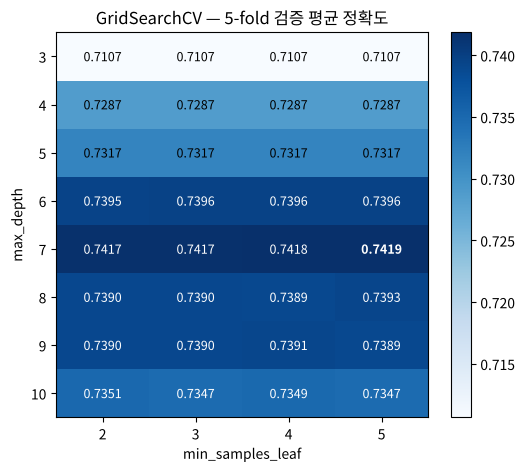

In [13]:
# 검증 평균 정확도를 깊이 × 리프 표로
table = results.pivot(index='param_max_depth', columns='param_min_samples_leaf', values='mean_test_score')

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(table, cmap='Blues', aspect='auto')
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.iloc[i, j]
        ax.text(j, i, f'{v:.4f}', ha='center', va='center', fontsize=9,
                color='white' if v > table.values.mean() else 'black',
                weight='bold' if v == table.values.max() else 'normal')
ax.set_xticks(range(table.shape[1]), table.columns)
ax.set_yticks(range(table.shape[0]), table.index)
ax.set_xlabel('min_samples_leaf'); ax.set_ylabel('max_depth')
ax.set_title('GridSearchCV — 5-fold 검증 평균 정확도')
plt.colorbar(im, ax=ax)
plt.show()

![GridSearchCV 애니메이션](./images/anim_03_gridsearch.gif)

🎬 32개 조합을 하나씩 5-fold 로 평가하며 표를 채운다. 가장 좋은 칸 = **`max_depth=7`, `min_samples_leaf=5` (0.7419)**.

- 점수를 가르는 건 거의 **`max_depth`** 다. `min_samples_leaf` 2 ~ 5 는 소수 넷째 자리만 다르다 — 깊이 7 트리의 리프 126개는 **절반이 약 200명 이상**이고, 5명 제한에 실제로 걸리는 리프는 **2개뿐**이라 2 ~ 5 명 제한은 거의 영향이 없다.
- 그래서 후보 범위가 중요하다. `min_samples_leaf` 를 **[2, 5, 20, 50, 100, 200, 500]** 처럼 넓게 잡아 보자(아래).

In [14]:
# 깊이를 7 로 고정하고 min_samples_leaf 범위를 넓게
for leaf in [2, 5, 20, 50, 100, 200, 500]:
    s = cross_val_score(DecisionTreeClassifier(max_depth=7, min_samples_leaf=leaf, random_state=0),
                        X_train, y_train, cv=5).mean()
    print(f"min_samples_leaf={leaf:>3} : 검증 평균 {s:.4f}")

min_samples_leaf=  2 : 검증 평균 0.7417


min_samples_leaf=  5 : 검증 평균 0.7419


min_samples_leaf= 20 : 검증 평균 0.7417


min_samples_leaf= 50 : 검증 평균 0.7424


min_samples_leaf=100 : 검증 평균 0.7427


min_samples_leaf=200 : 검증 평균 0.7405


min_samples_leaf=500 : 검증 평균 0.7364


`min_samples_leaf=100` 이 **0.7427** 로 원래 탐색의 최고(0.7419)보다 조금 높다(0.1%p 미만이라 실질적 차이는 작다). GridSearchCV 는 **준 후보 안에서만** 고르므로, 먼저 넓은 간격(2, 20, 200 …)으로 훑고 좋은 구간을 촘촘히 다시 탐색하는 것이 요령이다. 너무 크면(500) 다시 떨어진다 — 과소적합.

### 4-2. 깊이에 따른 학습 · 검증 점수 — 과대적합이 시작되는 곳

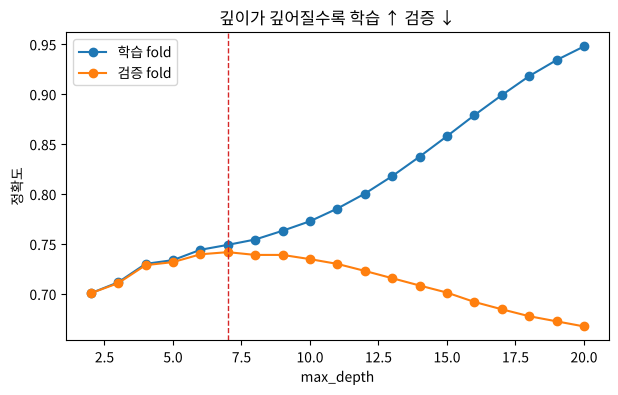

검증 최고 깊이 : {'max_depth': 7} 0.7417


In [15]:
grid_depth = GridSearchCV(DecisionTreeClassifier(random_state=0),
                          {'max_depth': list(range(2, 21))}, cv=5, return_train_score=True)
grid_depth.fit(X_train, y_train)
r = pd.DataFrame(grid_depth.cv_results_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(r['param_max_depth'], r['mean_train_score'], marker='o', label='학습 fold')
ax.plot(r['param_max_depth'], r['mean_test_score'], marker='o', label='검증 fold')
ax.axvline(grid_depth.best_params_['max_depth'], color='tab:red', ls='--', lw=1)
ax.set_xlabel('max_depth'); ax.set_ylabel('정확도'); ax.legend()
ax.set_title('깊이가 깊어질수록 학습 ↑ 검증 ↓')
plt.show()
print("검증 최고 깊이 :", grid_depth.best_params_, round(grid_depth.best_score_, 4))

![깊이 곡선 애니메이션](./images/anim_04_depth_curve.gif)

🎬 깊이를 2 → 20 으로 늘리면 학습 점수(파랑)는 계속 오르지만 검증 점수(주황)는 **깊이 7 (0.742)** 에서 꺾여 깊이 20 에서는 0.667 — 두 선 사이(색칠)가 벌어지는 만큼이 **과대적합**. 메모의 "과대적합 : 특성을 전부 반영 → 매우 깊은 의사결정 → 학습용은 정확, 평가용은 안 맞는다"를 그림으로 본 것.

## 5. 정리 — 같은 당뇨병 데이터, 지금까지의 모델

| 모델 | 고른 방법 | 평가용 정확도 |
|---|---|---|
| 결정 트리 기본값 (깊이 37) | — | 0.6545 |
| 결정 트리 `max_depth=7, min_samples_leaf=5` | **GridSearchCV (5-fold)** | **0.7411** |
| 랜덤 포레스트 기본값 ([Day 024](../../2026-10-13/)) | — | 0.7402 |
| XGBoost ([Day 025](../../2026-10-14/)) | — | 0.7498 |

- 트리 하나를 **교차 검증으로 잘 고르기만 해도** 기본값 랜덤 포레스트와 같은 수준.
- 같은 방법으로 랜덤 포레스트의 `n_estimators` · `max_depth` 나 XGBoost 의 `learning_rate` 도 고를 수 있다 — `estimator` 와 `param_grid` 만 바꾸면 된다([Day 024](../../2026-10-13/) 복습 질문).
- 후보가 많아지면 조합이 곱으로 늘어난다(3개 × 3개 × 3개 × 5-fold = 135번). 그럴 땐 무작위로 일부만 보는 `RandomizedSearchCV` 를 쓴다.